# 01 · Base de conhecimento e busca

**Critérios da rubrica:** 02 (base de conhecimento, em trechos com fonte) e 03 (busca com recall@1 e recall@3 medidos e limiar justificado).

Este notebook mostra a base, mede a busca e calibra o limiar de recusa. Tudo roda na máquina local, com o modelo de embeddings `bge-m3` servido pelo Ollama.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
from consultor import config
print("modelo:", config.MODELO_LLM, "| embeddings:", config.MODELO_EMBEDDING, "| limiar de recusa:", config.limiar_recusa())

modelo: qwen2.5:7b | embeddings: bge-m3 | limiar de recusa: 0.56


## 1. A base: fontes, formato, licença e número de trechos

Cada trecho guarda o documento de origem e o ponto exato dentro dele (`localizador`). Trechos de fontes com licença que permite cópia (portal gov.br, CC BY-ND 3.0) e de atos oficiais são transcrições com cortes mínimos. Trechos do livro do PROCEL e da página da EPE são sínteses escritas pelo grupo, marcadas com "Síntese:".

In [2]:
from consultor.base import tabela_da_base, carregar_trechos
tabela = pd.DataFrame(tabela_da_base())
display(tabela[["orgao", "titulo", "formato", "licenca", "tipo_trecho", "n_trechos"]])
trechos = carregar_trechos()
tamanhos = pd.Series([len(t.texto) for t in trechos])
print(f"{len(tabela)} fontes, {len(trechos)} trechos")
print(f"tamanho dos trechos em caracteres: mínimo {tamanhos.min()}, mediana {int(tamanhos.median())}, máximo {tamanhos.max()}")

,orgao,titulo,formato,licenca,tipo_trecho,n_trechos
0,ANEEL,Bandeiras Tarifárias,HTML,CC BY-ND 3.0 (portal gov.br),literal,3
1,ANEEL,Tarifa Branca,HTML,CC BY-ND 3.0 (portal gov.br),literal,3
2,ANEEL,Perguntas frequentes sobre Tarifa Branca,HTML,CC BY-ND 3.0 (portal gov.br),literal,6
3,ANEEL,Postos Tarifários,HTML,CC BY-ND 3.0 (portal gov.br),literal,3
4,ANEEL,Modalidades Tarifárias,HTML,CC BY-ND 3.0 (portal gov.br),literal,2
5,ANEEL,Programa de Eficiência Energética (PEE),HTML,CC BY-ND 3.0 (portal gov.br),literal,1
6,ANEEL,Chamadas Públicas do PEE,HTML,CC BY-ND 3.0 (portal gov.br),literal,1
7,Ministério de Minas e Energia (MME),"Programa de Eficiência Energética (PEE) da ANEEL — Guia de Eficiência Energética para Municípios, vol. III",HTML,CC BY-ND 3.0 (portal gov.br),literal,2
8,Anvisa / Ministério da Saúde,"Resolução RDC nº 216, de 15 de setembro de 2004 — Regulamento Técnico de Boas Práticas para Serviços de Alimentação",HTML,"Ato oficial, sem proteção autoral (Lei 9.610/1998, art. 8º, IV)",literal,7
9,Eletrobras / PROCEL,Eficiência Energética em Sistemas de Refrigeração Industrial e Comercial (Venturini e Pirani),"PDF (livro técnico, 2005)",Direitos reservados à Eletrobras/PROCEL; usada apenas como síntese própria com citação da página,sintese,11


14 fontes, 56 trechos
tamanho dos trechos em caracteres: mínimo 197, mediana 406, máximo 722


In [3]:
for t in (trechos[1], trechos[28]):
    print(f"[{t.id}] {t.titulo}")
    print("  localizador:", t.localizador)
    print("  texto:", t.texto[:330], "...")
    print()

[aneel-bandeiras-02] Bandeiras Tarifárias — o que significa cada cor e quanto custa
  localizador: seção 'O que significa cada cor e quanto custa?'
  texto: Bandeira verde: condições favoráveis de geração de energia. A tarifa não sofre nenhum acréscimo. Bandeira amarela: condições de geração menos favoráveis. A tarifa sofre acréscimo de R$ 0,01885 para cada quilowatt-hora (kWh) consumido. Bandeira vermelha - Patamar 1: condições mais custosas de geração. A tarifa sofre acréscimo de  ...

[procel-refrigeracao-01] Refrigeração comercial — por que porta aberta gasta energia (infiltração de ar)
  localizador: seção 2.4.5, p. 73
  texto: Síntese: cada vez que a porta de um espaço refrigerado é aberta, entra ar externo quente e sai ar frio. Esse ar que entrou precisa ser resfriado pelo sistema frigorífico, o que aumenta a carga térmica e, com ela, o consumo de energia do compressor. Quanto mais vezes e por mais tempo a porta fica aberta, maior a carga de infiltra ...



## 2. Casos de teste

Os casos ficam em `avaliacao/casos_teste.jsonl`. O conjunto de **calibração** serve para ajustar o limiar e os prompts. O conjunto de **teste** só é usado para medir, depois que tudo foi congelado.

In [4]:
from consultor import avaliacao
casos = avaliacao.carregar_casos()
quadro = pd.DataFrame([{"conjunto": c.conjunto, "categoria": c.categoria} for c in casos])
display(pd.crosstab(quadro["conjunto"], quadro["categoria"], margins=True, margins_name="total"))
exemplo = next(c for c in casos if c.id == "t07")
print("exemplo respondível :", exemplo.pergunta, "->", exemplo.gabarito, "| trechos:", exemplo.trechos_relevantes)
exemplo = next(c for c in casos if c.id == "t34")
print("exemplo 'não consta':", exemplo.pergunta, "->", exemplo.gabarito)

categoria,calculo,factual,loja,nao_consta,total
conjunto,,,,,
calibracao,3,16,2,9,30
teste,6,20,6,12,44
total,9,36,8,21,74


exemplo respondível : Se eu sair da tarifa branca e me arrepender, quando posso aderir de novo? -> Só depois de 180 dias do retorno à tarifa convencional. | trechos: ('aneel-tb-faq-05',)
exemplo 'não consta': Qual percentual da receita as distribuidoras são obrigadas a investir no Programa de Eficiência Energética? -> Não consta na base (a base cita a Lei 9.991/2000, mas não o percentual).


## 3. recall@1 e recall@3

recall@k é a fração das perguntas em que pelo menos um trecho relevante (marcado no gabarito) aparece entre os k primeiros resultados. Só entram perguntas respondíveis que têm trecho relevante na base.

Comparamos duas buscas: **BM25** (por palavras) e **densa** (embeddings `bge-m3` com similaridade de cosseno).

In [5]:
sys.path.insert(0, str(RAIZ / "scripts"))
import avaliar_busca
medida = avaliar_busca.main()

bm25   calibracao  n=19  recall@1=0.789  recall@3=0.895
bm25   teste       n=28  recall@1=0.786  recall@3=0.857


denso  calibracao  n=19  recall@1=0.789  recall@3=0.947


denso  teste       n=28  recall@1=0.786  recall@3=0.929


limiar escolhido na calibração: {'limiar': 0.56, 'menor_score_respondivel': 0.5792, 'margem': 0.02, 'respondiveis_mantidas_%': 100.0, 'nao_consta_barradas_%': 88.9, 'acuracia_balanceada': 0.944}
efeito no conjunto de teste:    {'limiar': 0.56, 'respondiveis_mantidas_%': 88.5, 'nao_consta_barradas_%': 91.7, 'acuracia_balanceada': 0.901}


In [6]:
linhas = []
for chave, r in medida["recall"].items():
    nome, conjunto = chave.split("_")
    linhas.append({"busca": nome, "conjunto": conjunto, "perguntas": r["n"], "recall@1": r["recall@1"], "recall@3": r["recall@3"]})
display(pd.DataFrame(linhas))
perdidos = [d for d in medida["recall"]["denso_teste"]["detalhe"] if d["posicao_primeiro_relevante"] is None]
print("Perguntas do teste em que a busca densa não trouxe nenhum trecho relevante no top 3:")
for d in perdidos:
    caso = next(c for c in casos if c.id == d["caso"])
    print(f"  {d['caso']} ({caso.categoria}): {caso.pergunta}")
    print(f"     recuperou {d['recuperados']}  |  esperado {list(caso.trechos_relevantes)}")

,busca,conjunto,perguntas,recall@1,recall@3
0,bm25,calibracao,19,0.789,0.895
1,bm25,teste,28,0.786,0.857
2,denso,calibracao,19,0.789,0.947
3,denso,teste,28,0.786,0.929


Perguntas do teste em que a busca densa não trouxe nenhum trecho relevante no top 3:
  t27 (loja): Qual equipamento da padaria-01 mais desperdiçou energia em 2026-10 e o que devo fazer?
     recuperou ['produto-contrato-05', 'procel-refrigeracao-08', 'ana-dicas-03']  |  esperado ['resumo:padaria-01:2026-10', 'procel-refrigeracao-01', 'procel-refrigeracao-03', 'ana-a3p-01', 'ana-a3p-02']
  t28 (loja): Qual foi o maior desperdício do mercado-01 em 2026-10 e qual é a recomendação?
     recuperou ['procel-refrigeracao-09', 'produto-contrato-05', 'produto-contrato-04']  |  esperado ['resumo:mercado-01:2026-10', 'ana-dicas-02', 'ana-a3p-03']


## 4. Limiar de recusa

Se o melhor trecho tem similaridade abaixo do limiar, o sistema responde "não consta" sem chamar a LLM.

**Critério de escolha, fixado antes de olhar o teste:** o maior limiar que não barra nenhuma pergunta respondível da calibração, menos uma margem de 0,02. O motivo é o custo de cada erro. Barrar uma pergunta legítima deixa o comerciante sem resposta e não tem segunda chance. Deixar passar uma pergunta sem resposta não é fatal: ela ainda é lida pela LLM (que pode recusar) e pelo verificador de citação.

Perguntas sobre uma loja ficam fora dessa calibração, porque a resposta delas está no resumo da loja e não na base.

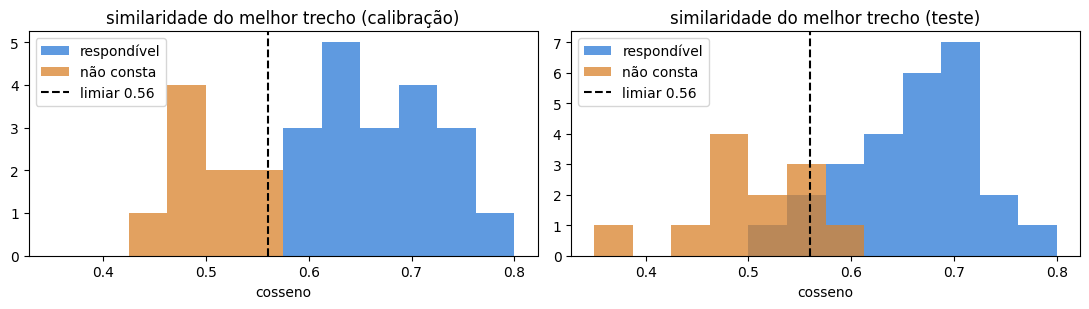

In [7]:
import matplotlib.pyplot as plt
cal = pd.DataFrame(medida["scores_calibracao"]); tes = pd.DataFrame(medida["scores_teste"])
limiar = medida["limiar"]["limiar"]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for eixo, quadro, titulo in ((eixos[0], cal, "calibração"), (eixos[1], tes, "teste")):
    quadro = quadro[quadro["categoria"] != "loja"]
    eixo.hist(quadro[~quadro["nao_consta"]]["score"], bins=12, range=(0.35, 0.80), alpha=0.75, label="respondível", color="#2a78d6")
    eixo.hist(quadro[quadro["nao_consta"]]["score"], bins=12, range=(0.35, 0.80), alpha=0.75, label="não consta", color="#d9822b")
    eixo.axvline(limiar, color="black", linestyle="--", label=f"limiar {limiar}")
    eixo.set_title(f"similaridade do melhor trecho ({titulo})"); eixo.set_xlabel("cosseno"); eixo.legend()
plt.tight_layout(); plt.savefig(RAIZ / "avaliacao" / "limiar.png", dpi=130); plt.show()

In [8]:
grade = []
for valor in (0.40, 0.45, 0.50, 0.53, limiar, 0.60, 0.65):
    c = avaliacao.avaliar_limiar([x for x in medida["scores_calibracao"] if x["categoria"] != "loja"], valor)
    t = avaliacao.avaliar_limiar([x for x in medida["scores_teste"] if x["categoria"] != "loja"], valor)
    grade.append({"limiar": valor, "calibração: respondíveis mantidas %": c["respondiveis_mantidas_%"], "calibração: não consta barradas %": c["nao_consta_barradas_%"],
                  "teste: respondíveis mantidas %": t["respondiveis_mantidas_%"], "teste: não consta barradas %": t["nao_consta_barradas_%"]})
display(pd.DataFrame(grade).sort_values("limiar"))
print("limiar escolhido:", medida["limiar"])
print("efeito no teste :", medida["limiar_no_teste"])
barradas = tes[(~tes["nao_consta"]) & (tes["categoria"] != "loja") & (tes["score"] < limiar)]
print("perguntas respondíveis do teste barradas pelo limiar:", list(barradas["caso"]))

,limiar,calibração: respondíveis mantidas %,calibração: não consta barradas %,teste: respondíveis mantidas %,teste: não consta barradas %
0,0.40,100.0,0.0,100.0,8.3
1,0.45,100.0,0.0,100.0,8.3
2,0.50,100.0,55.6,100.0,50.0
3,0.53,100.0,77.8,100.0,66.7
4,0.56,100.0,88.9,88.5,91.7
5,0.60,84.2,100.0,84.6,100.0
6,0.65,57.9,100.0,61.5,100.0


limiar escolhido: {'limiar': 0.56, 'menor_score_respondivel': 0.5792, 'margem': 0.02, 'respondiveis_mantidas_%': 100.0, 'nao_consta_barradas_%': 88.9, 'acuracia_balanceada': 0.944}
efeito no teste : {'limiar': 0.56, 'respondiveis_mantidas_%': 88.5, 'nao_consta_barradas_%': 91.7, 'acuracia_balanceada': 0.901}
perguntas respondíveis do teste barradas pelo limiar: ['t16', 't21', 't24']


**Leitura.** Na calibração o limiar separa bem os dois grupos. No teste ele continua barrando a maior parte das perguntas sem resposta, mas também barra algumas perguntas legítimas cuja redação é distante do texto da base. Essas recusas indevidas aparecem no placar (notebook 04) e uma delas é analisada entre os cinco erros. O limiar sozinho não separa perguntas do mesmo assunto que a base não cobre (por exemplo, o valor de uma tarifa específica): para essas, a recusa vem da LLM instruída a só responder com evidência.